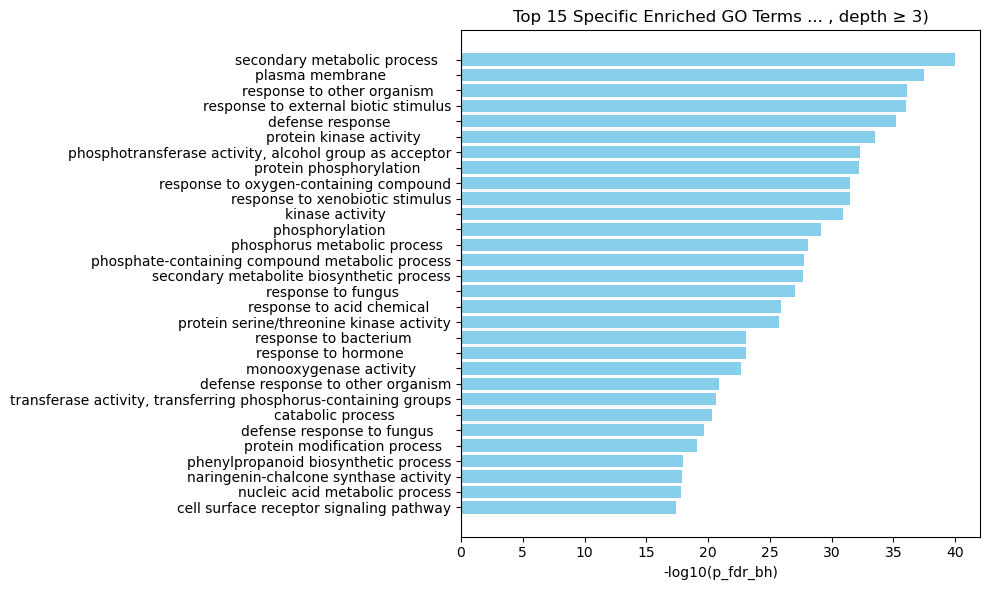

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from io import StringIO

# Step 1: Load the GOATOOLS results
data_lines = []
with open("/home/newol210/macknight_oliver/GOATOOLS_working_dir/goatools_output_test2", "r") as f:
    for line in f:
        if line.startswith("GO:"):
            data_lines.append(line.strip())

cleaned_data = "\n".join(data_lines)
df = pd.read_csv(StringIO(cleaned_data), sep="\t", header=None)
df.columns = ["GO", "NS", "ep", "name", "study", "pop", "p_uncorrected", "depth",
              "n_study", "p_bonferroni", "p_sidak", "p_holm", "p_fdr_bh", "study_items"]

# Convert columns to numeric
df["p_fdr_bh"] = pd.to_numeric(df["p_fdr_bh"], errors="coerce")
df["p_uncorrected"] = pd.to_numeric(df["p_uncorrected"], errors="coerce")
df["depth"] = pd.to_numeric(df["depth"], errors="coerce")

# Step 2: Filter out high-level GO terms (depth < 3)
filtered_df = df[df["depth"] >= 3].copy()

# Step 3: Use adjusted p-values if available
sig_df = filtered_df[filtered_df["p_fdr_bh"] < 0.05].copy()
sig_df["-log10(p_fdr_bh)"] = -np.log10(sig_df["p_fdr_bh"])
top15 = sig_df.sort_values("p_fdr_bh").head(30) # this can be edited to give the number of top significant terms you want

# Fallback to raw p-values if FDR is empty
if top15.empty:
    filtered_df["-log10(p_uncorrected)"] = -np.log10(filtered_df["p_uncorrected"])
    top15 = filtered_df.sort_values("p_uncorrected").head(15)
    log_col = "-log10(p_uncorrected)"
    label = "Raw p-values"
else:
    log_col = "-log10(p_fdr_bh)"
    label = "FDR-adjusted p-values"

# Step 4: Plot
#plt.figure(figsize=(10, 6))
#plt.barh(top15["name"], top15[log_col], color="skyblue")
#plt.xlabel(log_col)
#plt.title(f"Top 30 Enriched GO Terms linked to genes upregulated in high-pigment samples relative to unpigmented ({label}, depth ≥ 3)")
#plt.gca().invert_yaxis()
#plt.tight_layout()
#plt.show()

# Step 4: Plot
plt.figure(figsize=(10, 6))
ax = plt.gca()

ax.barh(top15["name"], top15[log_col], color="skyblue")
ax.set_xlabel(log_col)
ax.set_title(f"Top 15 Specific Enriched GO Terms ... , depth ≥ 3)")
ax.invert_yaxis()

# Align y-axis labels to the right
ax.set_yticks(range(len(top15)))
ax.set_yticklabels(top15["name"], ha="right")

plt.tight_layout()

# Save as SVG
plt.savefig("GO_enrichment_top15.svg", format="svg")

plt.show()